# Notebook 4 — Validación semisintética (OE6 · bloque R6)

**Pregunta:** *¿funciona el método cuando conocemos la respuesta?*

Se conservan las **covariables reales** (N = 2 220 avisos ROOFTOP, sus ubicaciones, edificios y bloques) y se simulan el tratamiento y el
resultado con un efecto **conocido** θ₀ = 0,05 (≈ 5,1 % por baño). Las funciones m₀(X) = E[T|X] y g₀(X) se ajustan una vez sobre los datos
reales, de modo que la confusión observada tiene la forma no lineal del mercado limeño. Luego se plantan, por escenario:

| Escenario | Qué se planta | Qué debería pasar |
|---|---|---|
| E1 | Nada (solo confusión observada) | DML insesgado y cobertura ≈ 95 %; el control inadmisible (precio/m²) sesga |
| E2–E4 | Confusor omitido U con R² parcial ≈ 0,02 / 0,07 / 0,15 con T y con Y | DML sesgado hacia arriba, creciente con la fuerza de U; la cota de sensibilidad debe contener θ₀ |
| E5 | θ heterogéneo: 0,03 (clase1), 0,05 (clase2), 0,08 (clase3) | GATE recupera cada θ_g; la prueba de Wald detecta diferencias |
| E6 | Shocks comunes por bloque de 1 km en T y en Y | EE iid subcubren; EE agrupados deben corregirlo |

100 réplicas por escenario. Estimadores: OLS sin ajustar, hedónico OLS con el conjunto S1, y DML-PLR (el mismo del notebook 3, con una
sola partición por réplica). Métricas: sesgo medio, RMSE, cobertura del IC 95 % y longitud media del IC.

> La simulación **no** demuestra que el efecto estimado en Lima sea causal; muestra si el software recupera el parámetro cuando el mundo
> generador es conocido y en qué escenarios falla.

In [1]:
import os, json, warnings; warnings.filterwarnings("ignore")
os.environ["OMP_NUM_THREADS"] = "2"; os.environ["PYTHONPATH"] = os.getcwd()
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from joblib import Parallel, delayed
from sklearn.model_selection import cross_val_predict
from causal_utils import *
import semisintetico as ss

sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
ORIGEN = "notebook4_semisintetico.ipynb"
base = pd.read_csv("../csv/data_causal_base.csv")
d = muestra(base); X = matriz(d); Xv = X.values
Y, T = d["Y"].values, d["T"].values
theta_hat = json.loads((RES / "resumen_principal.json").read_text(encoding="utf-8"))["theta"]

# Componentes del DGP ajustados sobre los datos reales
mod = LEARNERS["HGB"]
m0 = mod(SEED).fit(Xv, T).predict(Xv)
g0 = mod(SEED).fit(Xv, Y - theta_hat * T).predict(Xv)
sd_v = np.std(T - cross_val_predict(mod(SEED), Xv, T, cv=5))
sd_e = np.std(Y - theta_hat * T - cross_val_predict(mod(SEED), Xv, Y - theta_hat * T, cv=5))
ins = dict(m0=m0, g0=g0, sd_v=sd_v, sd_e=sd_e, clase=d["distrito_clase"].values,
           celda_codes=pd.factorize(d["celda_1km"])[0])
edif, celda, area = d["edificio_id"].values, d["celda_1km"].values, d["area"].values
verdad = {e: ss.theta_plr_verdadero(ins, e) for e in ss.ESCENARIOS}
print(f"N = {len(d)} | sd(v) = {sd_v:.3f} | sd(e) = {sd_e:.3f} | theta verdadero por escenario:", {k[:2]: round(v, 4) for k, v in verdad.items()})

N = 2220 | sd(v) = 0.491 | sd(e) = 0.243 | theta verdadero por escenario: {'E1': 0.05, 'E2': 0.05, 'E3': 0.05, 'E4': 0.05, 'E5': 0.0488, 'E6': 0.05}


In [2]:
import time
R = 100
t0 = time.time()
salida = Parallel(n_jobs=8, verbose=0)(delayed(ss.replica)(ins, e, r, Xv, area, edif, celda)
                                      for e in ss.ESCENARIOS for r in range(R))
print(f"{len(salida)} réplicas en {time.time() - t0:.0f} s")
est = pd.DataFrame([o for out, _ in salida for o in out])
aux = [a for _, a in salida]
est["verdad"] = est["escenario"].map(verdad)
est.to_csv(RES / "sim_replicas.csv", index=False)

600 réplicas en 256 s


In [3]:
def cubre(t, s, v):
    return np.where(np.isnan(s), np.nan, (t - 1.96 * s <= v) & (v <= t + 1.96 * s))

est["cob_edif"] = cubre(est.theta, est.se_edif, est.verdad)
est["cob_iid"] = cubre(est.theta, est.se_iid, est.verdad)
est["cob_celda"] = cubre(est.theta, est.se_celda, est.verdad)
est["long_ic"] = 2 * 1.96 * est.se_edif
orden_est = ["OLS sin ajustar", "Hedónico OLS (S1)", "DML PLR (S1)", "DML + precio/m² (inadmisible)"]
r6 = (est.groupby(["escenario", "estimador"], sort=False)
         .apply(lambda g: pd.Series({"verdad": g.verdad.iloc[0], "media theta": g.theta.mean(),
                                     "sesgo": (g.theta - g.verdad).mean(),
                                     "RMSE": np.sqrt(((g.theta - g.verdad) ** 2).mean()),
                                     "cobertura EE edificio": 100 * g.cob_edif.mean(),
                                     "cobertura EE iid": 100 * g.cob_iid.mean() if g.cob_iid.notna().any() else np.nan,
                                     "cobertura EE celda": 100 * g.cob_celda.mean() if g.cob_celda.notna().any() else np.nan,
                                     "long. media IC": g.long_ic.mean()}))
         .reset_index())
r6["estimador"] = pd.Categorical(r6["estimador"], orden_est)
r6 = r6.sort_values(["escenario", "estimador"]).reset_index(drop=True)
r6["estimador"] = r6["estimador"].astype(str)
guardar_tabla(r6, "R6_simulacion", origen=ORIGEN, decimales=3)
r6.round(3)

,escenario,estimador,verdad,media theta,sesgo,RMSE,cobertura EE edificio,cobertura EE iid,cobertura EE celda,long. media IC
0,E1 Sin U (efecto homogéneo),OLS sin ajustar,0.050,0.348,0.298,0.298,0.0,NaN,NaN,0.053
1,E1 Sin U (efecto homogéneo),Hedónico OLS (S1),0.050,0.072,0.022,0.024,50.0,NaN,NaN,0.043
2,E1 Sin U (efecto homogéneo),DML PLR (S1),0.050,0.049,-0.001,0.011,93.0,93.0,94.0,0.040
3,E1 Sin U (efecto homogéneo),DML + precio/m² (inadmisible),0.050,0.001,-0.049,0.049,0.0,0.0,NaN,0.007
4,"E2 U débil (R² ≈ 0,02)",OLS sin ajustar,0.050,0.352,0.302,0.302,0.0,NaN,NaN,0.052
5,"E2 U débil (R² ≈ 0,02)",Hedónico OLS (S1),0.050,0.079,0.029,0.031,19.0,NaN,NaN,0.043
6,"E2 U débil (R² ≈ 0,02)",DML PLR (S1),0.050,0.057,0.007,0.013,89.0,88.0,87.0,0.040
7,"E3 U moderado (R² ≈ 0,07)",OLS sin ajustar,0.050,0.360,0.310,0.310,0.0,NaN,NaN,0.052
8,"E3 U moderado (R² ≈ 0,07)",Hedónico OLS (S1),0.050,0.096,0.046,0.047,2.0,NaN,NaN,0.042
9,"E3 U moderado (R² ≈ 0,07)",DML PLR (S1),0.050,0.075,0.025,0.027,30.0,30.0,29.0,0.039


In [4]:
# Calibración de la sensibilidad: ¿la cota evaluada en la fuerza real de U contiene theta0?
sens = pd.DataFrame([a for a in aux if "cota" in a])
dml_u = est[(est.estimador == "DML PLR (S1)")].set_index(["escenario", "rep"])
sens["sesgo DML"] = [dml_u.loc[(e, r), "theta"] - ss.THETA0 for e, r in zip(sens.escenario, sens.rep)]
sens["cubre IC estándar"] = [bool(dml_u.loc[(e, r), "cob_edif"]) for e, r in zip(sens.escenario, sens.rep)]
r6s = (sens.groupby("escenario", sort=False)
           .agg(**{"R2 real de U con T": ("r2d_real", "mean"), "R2 real de U con Y": ("r2y_real", "mean"),
                   "sesgo medio DML": ("sesgo DML", "mean"), "cota media de sesgo": ("cota", "mean"),
                   "% cubre IC estándar": ("cubre IC estándar", lambda x: 100 * x.mean()),
                   "% cubre IC + cota de sensibilidad": ("cubre_sens", lambda x: 100 * x.mean())})
           .reset_index())
guardar_tabla(r6s, "R6_sensibilidad_calibracion", origen=ORIGEN)
r6s.round(4)

,escenario,R2 real de U con T,R2 real de U con Y,sesgo medio DML,cota media de sesgo,% cubre IC estándar,% cubre IC + cota de sensibilidad
0,"E2 U débil (R² ≈ 0,02)",0.0119,0.0175,0.0070,0.0067,89.0,96.0
1,"E3 U moderado (R² ≈ 0,07)",0.0409,0.0580,0.0246,0.0232,30.0,98.0
2,"E4 U fuerte (R² ≈ 0,15)",0.0876,0.1178,0.0537,0.0497,0.0,95.0


In [5]:
# Heterogeneidad (E5): ¿los GATE recuperan theta por clase?
gr = pd.DataFrame([dict(rep=a["rep"], **g) for a in aux if "gate" in a for g in a["gate"]])
gr["cubre"] = (gr.theta - 1.96 * gr.ee <= gr.verdad) & (gr.verdad <= gr.theta + 1.96 * gr.ee)
r6g = (gr.groupby("grupo")
         .agg(verdad=("verdad", "first"), **{"media GATE": ("theta", "mean"), "sesgo": ("theta", lambda x: 0)},
              RMSE=("theta", "std"), **{"cobertura IC 95 %": ("cubre", lambda x: 100 * x.mean())})
         .reset_index())
r6g["sesgo"] = r6g["media GATE"] - r6g["verdad"]
r6g["RMSE"] = gr.assign(e2=(gr.theta - gr.verdad) ** 2).groupby("grupo")["e2"].mean().pipe(np.sqrt).values
pot = np.mean([a["p_wald"] < 0.05 for a in aux if "p_wald" in a])
r6g["potencia Wald (p<0,05)"] = 100 * pot
guardar_tabla(r6g, "R6_gate", origen=ORIGEN)
r6g.round(4)

,grupo,verdad,media GATE,sesgo,RMSE,cobertura IC 95 %,"potencia Wald (p<0,05)"
0,clase1,0.03,0.0280,-0.0020,0.0152,93.0,49.0
1,clase2,0.05,0.0489,-0.0011,0.0184,94.0,49.0
2,clase3,0.08,0.0810,0.0010,0.0238,91.0,49.0


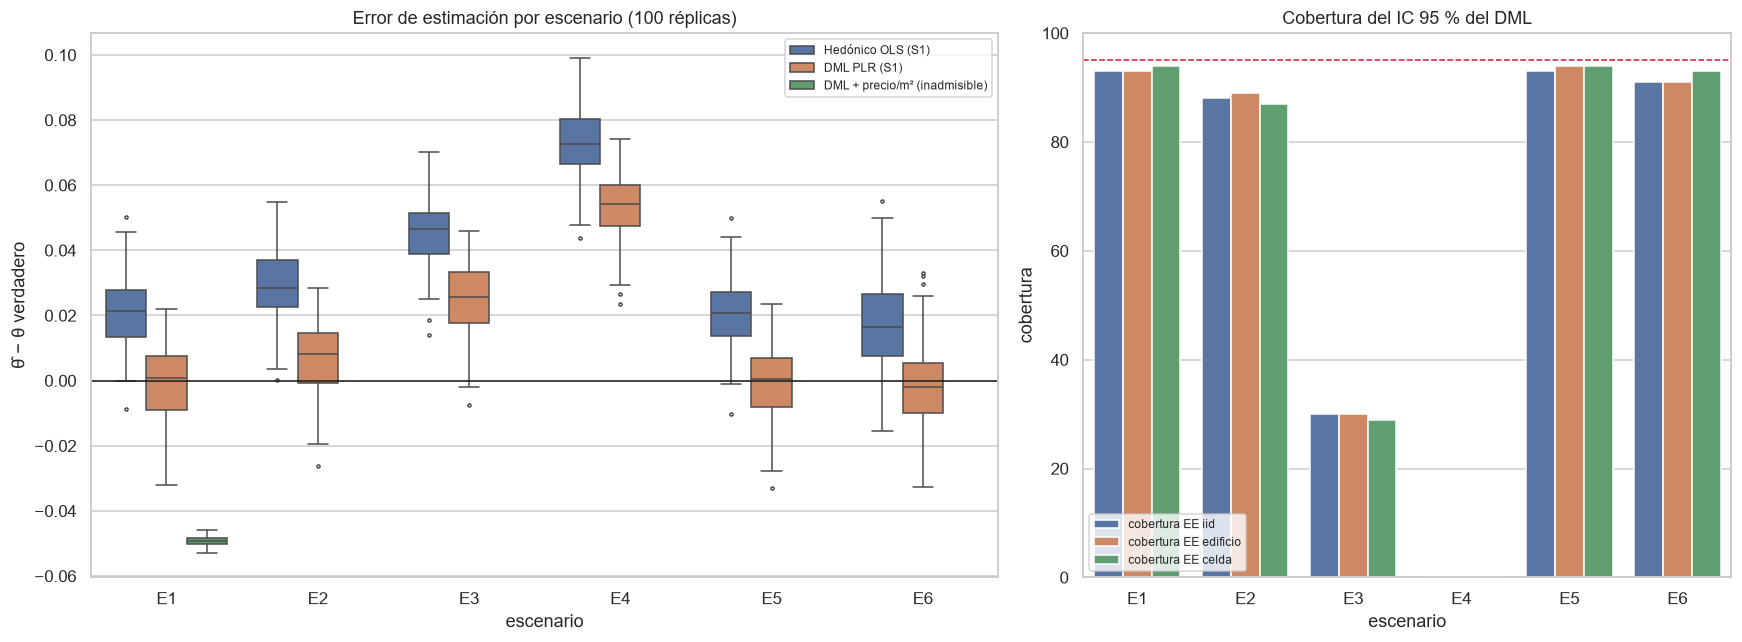

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})
sub = est[est.estimador.isin(["Hedónico OLS (S1)", "DML PLR (S1)", "DML + precio/m² (inadmisible)"])].copy()
sub["error"] = sub.theta - sub.verdad
sub["esc"] = sub.escenario.str.split(" ").str[0]
sns.boxplot(data=sub, x="esc", y="error", hue="estimador", ax=ax[0], fliersize=2)
ax[0].axhline(0, color="k", lw=1); ax[0].set_xlabel("escenario"); ax[0].set_ylabel("θ̂ − θ verdadero")
ax[0].set_title("Error de estimación por escenario (100 réplicas)"); ax[0].legend(fontsize=8)
c = r6[r6.estimador == "DML PLR (S1)"].copy(); c["esc"] = c.escenario.str.split(" ").str[0]
cc = c.melt(id_vars="esc", value_vars=["cobertura EE iid", "cobertura EE edificio", "cobertura EE celda"],
            var_name="inferencia", value_name="cobertura")
sns.barplot(data=cc, x="esc", y="cobertura", hue="inferencia", ax=ax[1])
ax[1].axhline(95, color="crimson", ls="--", lw=1); ax[1].set_ylim(0, 100); ax[1].set_xlabel("escenario")
ax[1].set_title("Cobertura del IC 95 % del DML"); ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(FIG / "F6_semisintetico.png", bbox_inches="tight"); plt.show()

## Tratamiento binario: cochera incluida (escenarios B1 y B2)

Mismo principio para el estimador del notebook 3b. Sobre los avisos con tratamiento de cochera definido se ajusta la propensión real
m₀(X) = P(cochera | X) y g₀(X). Luego se simula D ~ Bernoulli con logit m₀(X) + a·U, y Y = g₀(X) + 0.10·D + b·σ·U + ruido.
B1 no tiene confusor omitido (a = 0); B2 planta un U moderado (a = 0.8, b² = 0.07). En B2 se mide la fuerza real de U comparando con un
modelo que sí observa U, y se evalúa si la cota de sensibilidad contiene el efecto verdadero.

In [7]:
db = agregar_cochera(d).dropna(subset=["T_cochera"]).reset_index(drop=True)
NUM_C = ["area_log", "dormitorios", "banos", "antig", "antig_na", "latitud", "longitud", "dias_pub"]
Xb = matriz(db, NUM_C, CAT).values; Db = db["T_cochera"].astype(int).values; Yb = db["Y"].values
th_c = json.loads((RES / "resumen_cochera.json").read_text(encoding="utf-8"))["theta"]
p0 = np.clip(CLASIFICADOR(SEED).fit(Xb, Db).predict_proba(Xb)[:, 1], 0.02, 0.98)
g0b = LEARNERS["HGB"](SEED).fit(Xb, Yb - th_c * Db).predict(Xb)
sd_eb = np.std(Yb - th_c * Db - cross_val_predict(LEARNERS["HGB"](SEED), Xb, Yb - th_c * Db, cv=5))
insb = dict(logit_m0=np.log(p0 / (1 - p0)), g0=g0b, sd_e=sd_eb)
t0 = time.time()
salb = Parallel(n_jobs=8)(delayed(ss.replica_binaria)(insb, e, r, Xb, db["edificio_id"].values)
                          for e in ss.ESCENARIOS_B for r in range(R))
print(f"{len(salb)} réplicas binarias en {time.time() - t0:.0f} s (N = {len(db)})")
eb = pd.DataFrame([o for out, _ in salb for o in out]); ab = pd.DataFrame([a for _, a in salb])
eb["cubre"] = (eb.theta - 1.96 * eb.se <= ss.THETA_B) & (ss.THETA_B <= eb.theta + 1.96 * eb.se)
r6b = (eb.groupby(["escenario", "estimador"], sort=False)
         .apply(lambda g: pd.Series({"verdad": ss.THETA_B, "sesgo": (g.theta - ss.THETA_B).mean(),
                                     "RMSE": np.sqrt(((g.theta - ss.THETA_B) ** 2).mean()),
                                     "cobertura IC 95 %": 100 * g.cubre.mean(), "long. media IC": (2 * 1.96 * g.se).mean()}))
         .reset_index())
guardar_tabla(r6b, "R6b_simulacion_binaria", origen=ORIGEN)
display(r6b.round(4))
sb = ab.dropna(subset=["cota"]) if "cota" in ab else ab.iloc[0:0]
r6bs = pd.DataFrame({"indicador": ["% fuera de soporte común (promedio)", "R² real de U con D (cf_d)", "R² real de U con Y (cf_y)",
                                   "cota media de sesgo", "sesgo medio del IRM", "% cubre IC + cota de sensibilidad"],
                     "valor": [100 * ab["pct_fuera"].mean(), sb["cf_d"].mean(), sb["cf_y"].mean(), sb["cota"].mean(),
                               (eb[(eb.escenario.str.startswith("B2")) & (eb.estimador.str.startswith("DML-IRM"))].theta - ss.THETA_B).mean(),
                               100 * sb["cubre_sens"].mean()]})
guardar_tabla(r6bs, "R6b_sensibilidad", origen=ORIGEN)
r6bs.round(4)

200 réplicas binarias en 214 s (N = 2051)


,escenario,estimador,verdad,sesgo,RMSE,cobertura IC 95 %,long. media IC
0,B1 Binario sin U,Hedónico OLS,0.1,0.0002,0.0147,94.0,0.0579
1,B1 Binario sin U,DML PLR,0.1,-0.0040,0.0145,95.0,0.0549
2,B1 Binario sin U,DML-IRM (soporte común),0.1,-0.0036,0.0198,96.0,0.0805
3,B2 Binario con U moderado,Hedónico OLS,0.1,0.0412,0.0434,19.0,0.0566
4,B2 Binario con U moderado,DML PLR,0.1,0.0392,0.0418,20.0,0.0531
5,B2 Binario con U moderado,DML-IRM (soporte común),0.1,0.0421,0.0462,45.0,0.0777


,indicador,valor
0,% fuera de soporte común (promedio),7.5549
1,R² real de U con D (cf_d),0.0414
2,R² real de U con Y (cf_y),0.0421
3,cota media de sesgo,0.0240
4,sesgo medio del IRM,0.0421
5,% cubre IC + cota de sensibilidad,1.0000


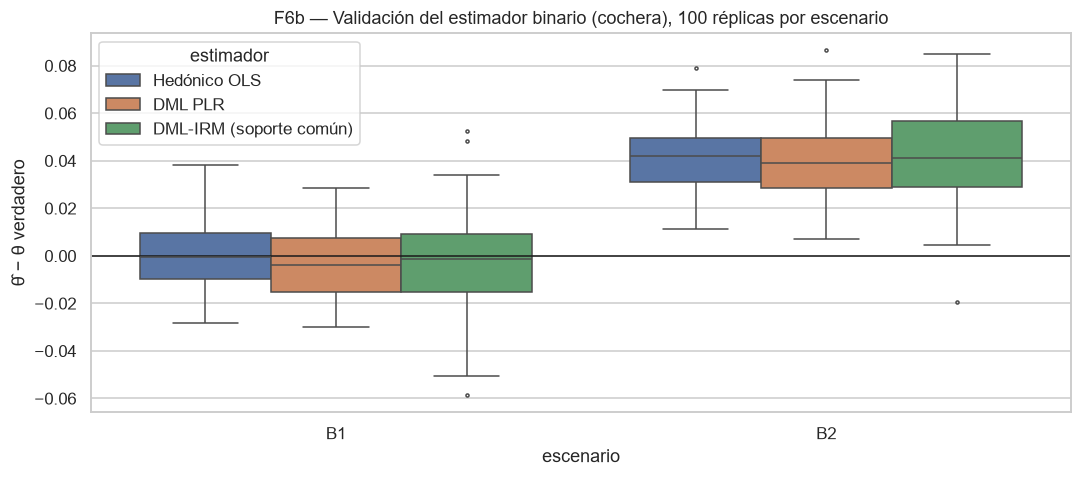

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
eb["error"] = eb.theta - ss.THETA_B; eb["esc"] = eb.escenario.str.split(" ").str[0]
sns.boxplot(data=eb, x="esc", y="error", hue="estimador", ax=ax, fliersize=2); ax.axhline(0, color="k", lw=1)
ax.set_xlabel("escenario"); ax.set_ylabel("θ̂ − θ verdadero"); ax.set_title("F6b — Validación del estimador binario (cochera), 100 réplicas por escenario")
plt.tight_layout(); plt.savefig(FIG / "F6b_semisintetico_binario.png", bbox_inches="tight"); plt.show()